# 02 · Feature Engineering

The EDA showed that degradation is a slow, noisy drift hidden under operating-regime effects. This notebook walks through the feature system implemented in `src/features/` — every block is a **scikit-learn compatible transformer** and every feature is **causal** (uses only the past of the same engine), so the exact same code runs in training and on a live data feed.

```
raw sensors ─► OperatingConditionNormalizer ─► TemporalFeatureGenerator ─► SensorInteractionFeatures   (unsupervised, fit once)
            ─► HealthIndicatorTransformer ─► FeatureSelector ─► model                                     (supervised, fit inside CV)
```

In [1]:
import sys, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_config
from src.utils import visualization as viz
from src.data.load_data import load_dataset
from src.data.preprocess import add_train_rul, split_engines, subsample_rows
from src.features.engineering import build_feature_pipeline, HealthIndicatorTransformer, describe_feature
from src.features.selection import FeatureSelector

cfg = load_config(ROOT / "config.yaml")
viz.set_style()
FIG = ROOT / cfg["paths"]["figures_dir"]
SEED, MAX_RUL = cfg["project"]["random_seed"], cfg["target"]["max_rul"]
SENSORS = cfg["data"]["sensors"]

ds = load_dataset("FD001", ROOT / cfg["paths"]["raw_dir"])
full = add_train_rul(ds.train, MAX_RUL)
train_df, val_df = split_engines(full, cfg["split"]["validation_fraction"], SEED)
print(f"{train_df.unit.nunique()} training engines / {val_df.unit.nunique()} validation engines")

00:15:52 | INFO    | src.data.load_data | Loaded FD001: 100 train engines (20631 rows), 100 test engines (13096 rows)


80 training engines / 20 validation engines


## 1. The unsupervised feature stage

In [2]:
feature_pipe = build_feature_pipeline(cfg, n_conditions=1)
t0 = time.time()
F = feature_pipe.fit(train_df).transform(train_df)
print(f"{F.shape[1] - 2} features for {len(F):,} rows in {time.time() - t0:.1f}s")

def family(col):
    for key in ["roll", "ewm", "lag", "diff", "slope", "ix_", "op_condition", "hist_share"]:
        if key in col:
            return {"roll": "rolling statistics", "ewm": "EWMA", "lag": "lags", "diff": "differences (1st/2nd)",
                    "slope": "rolling OLS slopes", "ix_": "sensor interactions", "op_condition": "regime one-hot",
                    "hist_share": "regime history"}[key]
    return "raw (normalised) sensors" if col.startswith("s") else "identifiers / age"
families = pd.Series({c: family(c) for c in F.columns}).value_counts().rename("n_features")
families.to_frame()

510 features for 16,390 rows in 1.7s


,n_features
rolling statistics,336
EWMA,42
lags,42
differences (1st/2nd),28
rolling OLS slopes,28
sensor interactions,20
raw (normalised) sensors,14
identifiers / age,2


### Causality — the property that makes this production-grade

A feature computed at cycle *t* on the full trajectory must be **identical** to the same feature computed when only cycles 1…*t* are available. Otherwise the model would be trained on information it will never have in service.

In [3]:
engine = train_df[train_df.unit == train_df.unit.iloc[0]]
gaps = []
for t in [20, 60, 120]:
    partial = feature_pipe.transform(engine[engine.cycle <= t]).iloc[-1]
    full_row = F.loc[engine.index[engine.cycle == t][0]]
    gaps.append({"truncated at cycle": t, "max |difference|": float(np.abs(partial.values - full_row.values).max())})
pd.DataFrame(gaps)

,truncated at cycle,max |difference|
0,20,0.0
1,60,0.0
2,120,0.0


Exactly zero: features are strictly causal. (The pipeline additionally checks at run time that the supervised stage is **row-wise**, i.e. predicting on the latest rows only equals predicting on full trajectories and sub-setting — a guard that caught a real bug during development: a health-indicator slope computed over the rows *received* rather than over the engine history silently degraded test RMSE from about 13 to about 21 cycles.)

### What the temporal features look like

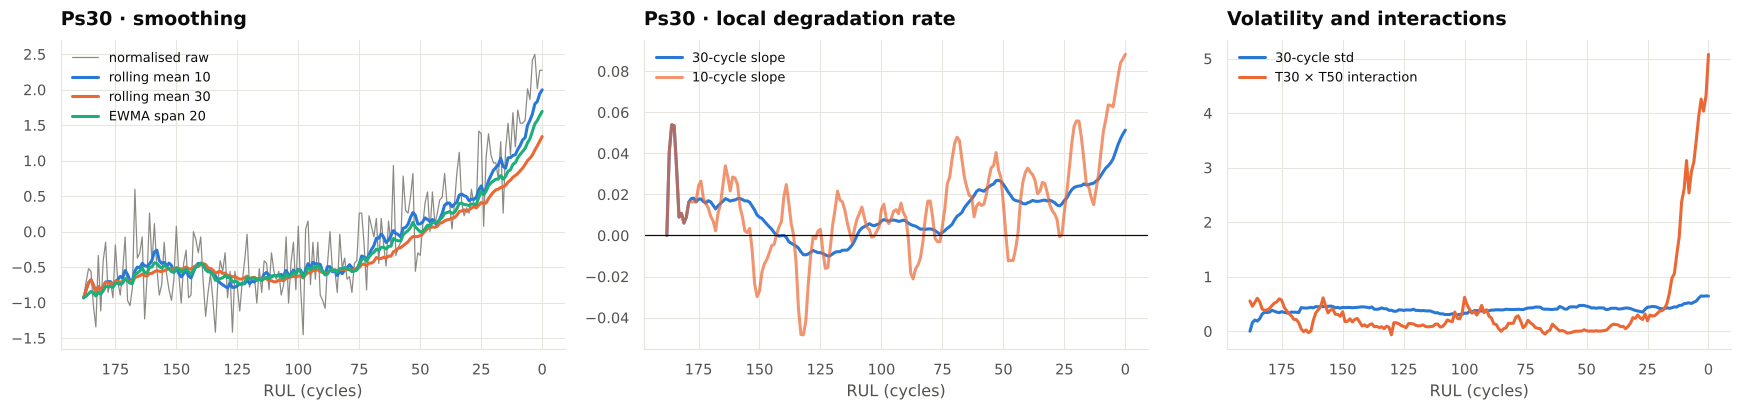

In [4]:
unit = train_df.unit.unique()[3]
m = (F.unit == unit).to_numpy()
rul = train_df.loc[m, "rul_true"]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
axes[0].plot(rul, F.loc[m, "s11"], color=viz.INK_3, lw=0.8, label="normalised raw")
for i, w in enumerate([10, 30]):
    axes[0].plot(rul, F.loc[m, f"s11_roll{w}_mean"], color=viz.PALETTE[i], label=f"rolling mean {w}")
axes[0].plot(rul, F.loc[m, "s11_ewm20"], color=viz.PALETTE[2], label="EWMA span 20")
axes[0].set(title="Ps30 · smoothing", xlabel="RUL (cycles)")
axes[1].plot(rul, F.loc[m, "s11_slope30"], color=viz.PALETTE[0], label="30-cycle slope")
axes[1].plot(rul, F.loc[m, "s11_slope10"], color=viz.PALETTE[1], alpha=0.7, label="10-cycle slope")
axes[1].axhline(0, color=viz.INK, lw=0.8)
axes[1].set(title="Ps30 · local degradation rate", xlabel="RUL (cycles)")
axes[2].plot(rul, F.loc[m, "s11_roll30_std"], color=viz.PALETTE[0], label="30-cycle std")
axes[2].plot(rul, F.loc[m, "ix_s3_x_s4"], color=viz.PALETTE[1], label="T30 × T50 interaction")
axes[2].set(title="Volatility and interactions", xlabel="RUL (cycles)")
for ax in axes:
    ax.invert_xaxis(); ax.legend(fontsize=8.5)
fig.tight_layout(); viz.save_figure(fig, "fe_temporal_features", FIG); plt.show()

## 2. Health indicator

A linear sensor-fusion model maps the 14 smoothed sensors onto `HI = min(RUL,125)/125` (1 = healthy, 0 = failure). Its weights are physically interpretable, and its slope is the single most informative degradation-rate feature.

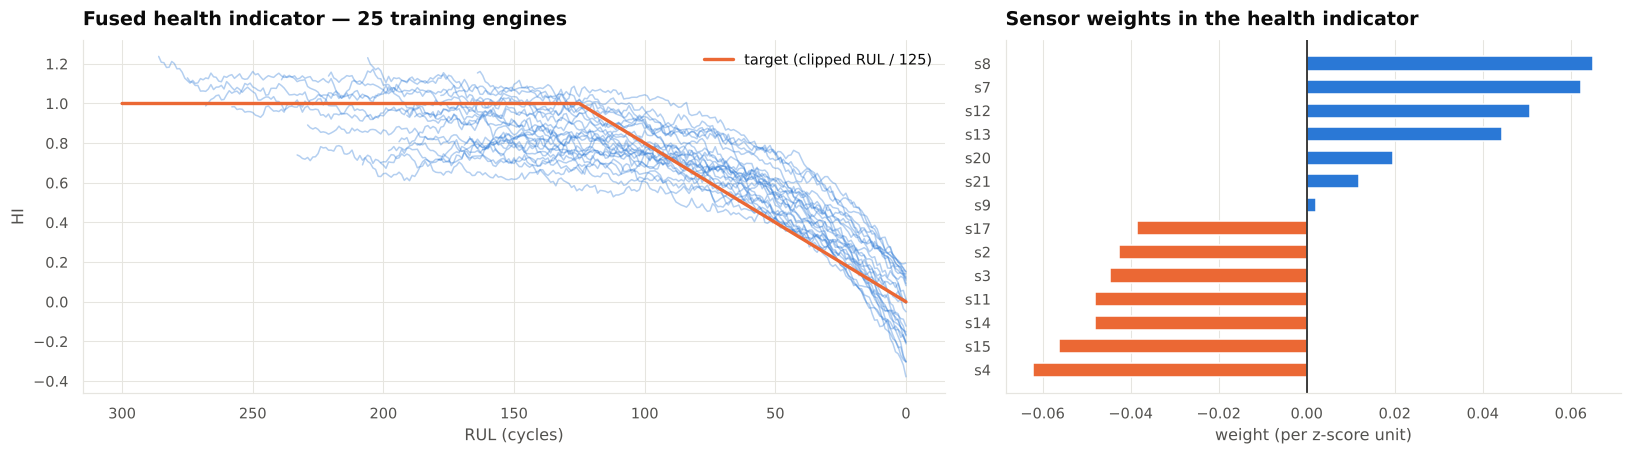

Correlation HI vs clipped RUL: 0.857


In [5]:
y = train_df["rul"].to_numpy()
hi = HealthIndicatorTransformer(SENSORS, span=10, max_rul=MAX_RUL,
                                ewm_spans=cfg["features"]["ewm_spans"],
                                slope_windows=cfg["features"]["slope_windows"]).fit(F, y)
H = hi.transform(F)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
for u in train_df.unit.unique()[:25]:
    mm = (H.unit == u).to_numpy()
    axes[0].plot(train_df.loc[mm, "rul_true"], H.loc[mm, "health_indicator"], color=viz.PALETTE[0], alpha=0.35, lw=1)
axes[0].plot([300, MAX_RUL, 0], [1, 1, 0], color=viz.PALETTE[1], lw=2.2, label="target (clipped RUL / 125)")
axes[0].invert_xaxis(); axes[0].legend()
axes[0].set(title="Fused health indicator — 25 training engines", xlabel="RUL (cycles)", ylabel="HI")
w = hi.weights_.sort_values()
axes[1].barh([describe_feature(s).split(" -")[0] for s in w.index], w.values,
             color=[viz.PALETTE[1] if v < 0 else viz.PALETTE[0] for v in w.values], height=0.6)
axes[1].axvline(0, color=viz.INK, lw=1)
axes[1].set(title="Sensor weights in the health indicator", xlabel="weight (per z-score unit)")
axes[1].grid(axis="y", visible=False)
fig.tight_layout(); viz.save_figure(fig, "fe_health_indicator", FIG); plt.show()
print("Correlation HI vs clipped RUL:", round(np.corrcoef(H.health_indicator, y)[0, 1], 3))

## 3. Which feature families carry the signal?

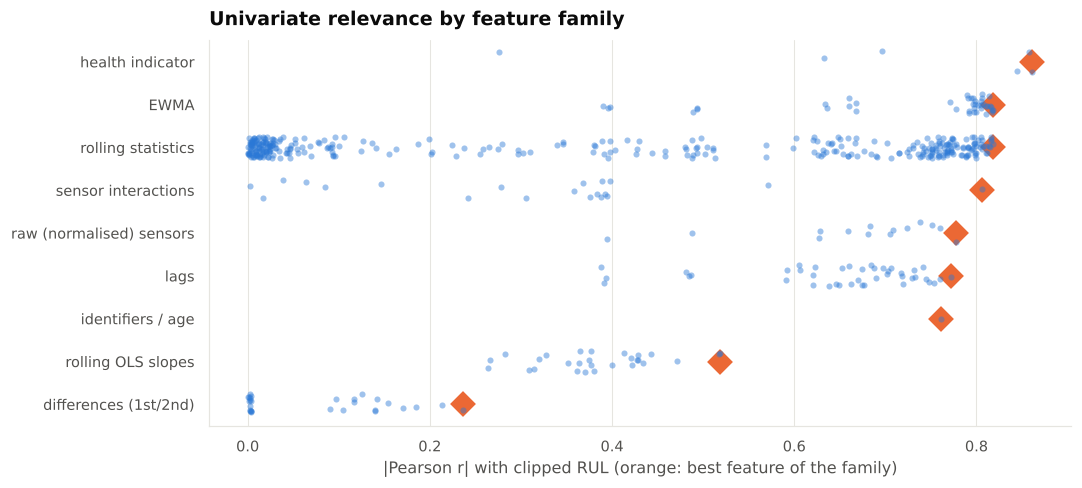

,abs_corr,family,description
health_indicator_ewm5,0.861143,health indicator,Health indicator - EWMA span 5
health_indicator,0.857255,health indicator,Health indicator (fused sensors)
health_indicator_ewm20,0.844034,health indicator,Health indicator - EWMA span 20
s4_ewm5,0.818000,EWMA,T50 (temp. LPT outlet) - EWMA (span 5)
s4_roll5_mean,0.817854,rolling statistics,T50 (temp. LPT outlet) - 5-cycle rolling mean
s17_ewm10,0.816769,EWMA,htBleed (Bleed enthalpy) - EWMA (span 10)
s4_ewm10,0.816561,EWMA,T50 (temp. LPT outlet) - EWMA (span 10)
s4_roll10_mean,0.816129,rolling statistics,T50 (temp. LPT outlet) - 10-cycle rolling mean
s11_roll5_mean,0.815964,rolling statistics,Ps30 (static pressure HPC outlet) - 5-cycle ro...
s17_roll10_mean,0.815932,rolling statistics,htBleed (Bleed enthalpy) - 10-cycle rolling mean


In [6]:
corr = H.drop(columns=["unit"]).corrwith(pd.Series(y, index=H.index)).abs()
fam = pd.DataFrame({"abs_corr": corr, "family": [family(c) if not c.startswith("health") else "health indicator" for c in corr.index]})
order = fam.groupby("family")["abs_corr"].max().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.stripplot(data=fam, y="family", x="abs_corr", order=order, ax=ax, color=viz.PALETTE[0], alpha=0.45, size=4, jitter=0.25)
sns.pointplot(data=fam, y="family", x="abs_corr", order=order, ax=ax, estimator="max", color=viz.PALETTE[1],
              linestyles="none", markers="D", errorbar=None)
ax.set(xlabel="|Pearson r| with clipped RUL (orange: best feature of the family)", ylabel="",
       title="Univariate relevance by feature family")
fig.tight_layout(); viz.save_figure(fig, "fe_family_relevance", FIG); plt.show()
fam.sort_values("abs_corr", ascending=False).head(10).assign(description=lambda d: [describe_feature(c) for c in d.index])

Smoothing pays off: EWMAs and rolling means correlate more strongly with RUL than the raw normalised sensors (noise averaging), and the fused health indicator (|r| ≈ 0.86) tops every single-sensor feature. Lags and short-window statistics are individually weak but redundant information is removed in the next step.

## 4. Feature selection

Three filters fitted on training data only: variance → greedy de-correlation (|r| < 0.98, most relevant first) → Extra-Trees importance (top-k).

engineered                     517
after redundancy filter        412
selected (top-k importance)    120


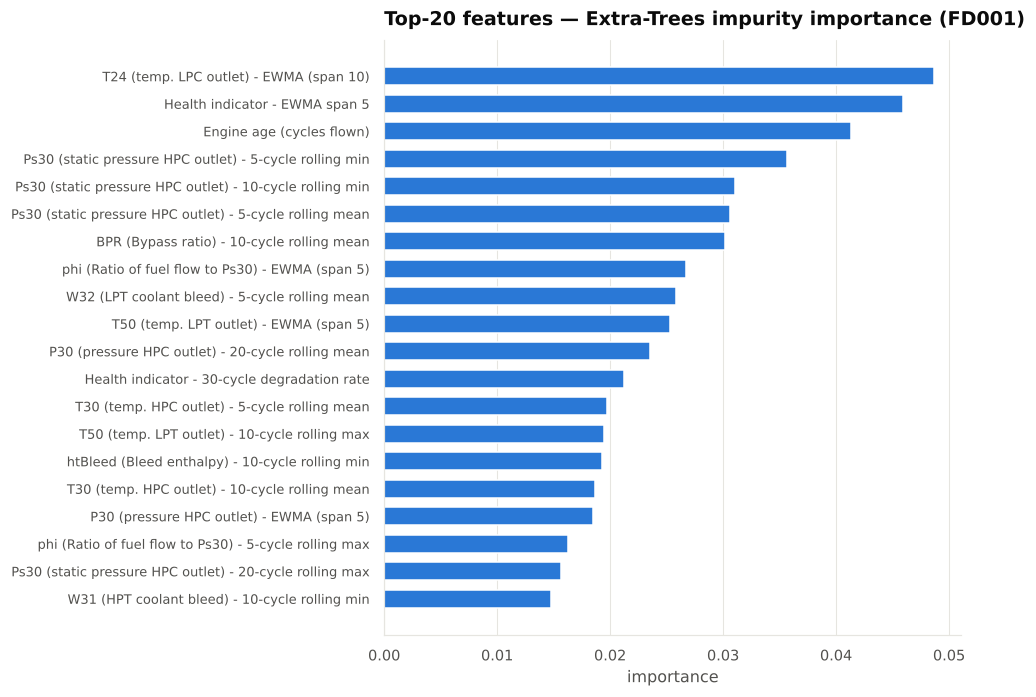

rolling statistics          73
rolling OLS slopes          17
sensor interactions          8
lags                         8
EWMA                         6
raw (normalised) sensors     4
health indicator             3
identifiers / age            1


In [7]:
idx = subsample_rows(train_df, cfg["split"]["train_row_stride"]).index
sel = FeatureSelector(top_k=cfg["selection"]["top_k"], correlation_threshold=cfg["selection"]["correlation_threshold"],
                      random_state=SEED).fit(H.loc[idx], y[train_df.index.get_indexer(idx)])
funnel = pd.Series({"engineered": sel.n_input_features_,
                    "after redundancy filter": sel.n_after_redundancy_,
                    "selected (top-k importance)": len(sel.selected_features_)})
print(funnel.to_string())
top = sel.importances_.head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh([describe_feature(c) for c in top.index], top.values, color=viz.PALETTE[0], height=0.65)
ax.set(title="Top-20 features — Extra-Trees impurity importance (FD001)", xlabel="importance")
ax.tick_params(axis="y", labelsize=8.5); ax.grid(axis="y", visible=False)
fig.tight_layout(); viz.save_figure(fig, "fe_selection_importance", FIG); plt.show()
print(pd.Series([family(c) if not c.startswith("health") else "health indicator" for c in sel.selected_features_]).value_counts().to_string())

## 5. Takeaways

* **~510 causal features** in about two seconds for 16 k rows; the generator is vectorised (grouped rolling + closed-form rolling OLS slopes).
* Regime normalisation, smoothing and sensor fusion turn weak, noisy sensors into features with |r| ≈ 0.82–0.86 with the target; the rest of the gain comes from non-linear models combining them.
* The supervised components (health indicator, selector) are fitted **inside** every cross-validation fold (see `src/models/train.py`), so no target information leaks into validation scores.
* Feature-family ablation (contribution of each family to final accuracy) is measured in notebook 03.